<a href="https://colab.research.google.com/github/vanesamrd/ML_ganjil/blob/main/Vanesa_JS05_T01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import hdbscan

In [2]:
!pip install hdbscan

In [4]:
# Mengambil dataset Iris dari URL publik karena file lokal 'iris.csv' tidak ditemukan
url = "https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv"
df = pd.read_csv(url)

df.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [5]:
# 1. Persiapan Data dan Standardisasi
# Pisahkan fitur numerik dan label asli
features = ['sepal.length', 'sepal.width', 'petal.length', 'petal.width']
X = df[features]
y = df['variety']

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
# 2. Reduksi Dimensi dengan PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Simpan ke DataFrame untuk kemudahan visualisasi
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
df_pca['variety'] = y

In [7]:
# 3. Clustering dengan HDBSCAN
# Menyetel min_cluster_size=5 dan min_samples=3 untuk dataset berukuran kecil seperti Iris
clusterer = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=3, gen_min_span_tree=True)
cluster_labels = clusterer.fit_predict(X_scaled)

df_pca['cluster'] = cluster_labels

In [ ]:
# 4. Melaporkan Hasil Clustering
n_clusters_ = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise_ = list(cluster_labels).count(-1)

print(f"=== HASIL CLUSTERING HDBSCAN ===")
print(f"Jumlah cluster yang terbentuk : {n_clusters_}")
print(f"Banyaknya data noise (label -1): {n_noise_} dari {len(df)} sampel")

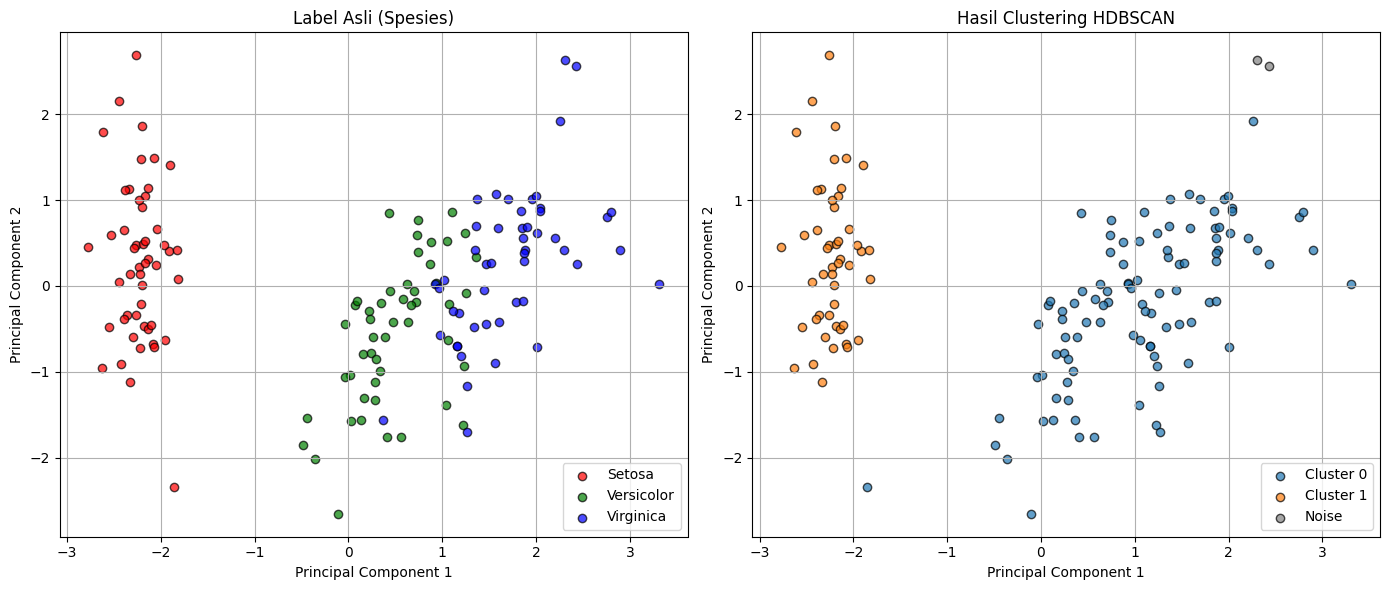

In [8]:
# 5. Visualisasi Hasil PCA
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Label Asli
colors = {'Setosa': 'red', 'Versicolor': 'green', 'Virginica': 'blue'}
for variety, group in df_pca.groupby('variety'):
    axes[0].scatter(group['PC1'], group['PC2'], label=variety, color=colors[variety], alpha=0.7, edgecolors='k')
axes[0].set_title('Label Asli (Spesies)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()
axes[0].grid(True)

# Plot Hasil Cluster HDBSCAN
# Cluster -1 adalah noise (biasanya abu-abu/hitam)
unique_clusters = set(cluster_labels)
for cluster in unique_clusters:
    group = df_pca[df_pca['cluster'] == cluster]
    label = f'Cluster {cluster}' if cluster != -1 else 'Noise'
    color = 'gray' if cluster == -1 else None
    axes[1].scatter(group['PC1'], group['PC2'], label=label, color=color, alpha=0.7, edgecolors='k')
axes[1].set_title('Hasil Clustering HDBSCAN')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [9]:
# 6. Analisis Kesesuaian Hasil (Cross-Tabulation)
ct = pd.crosstab(df_pca['variety'], df_pca['cluster'])
print("=== TABEL SILANG (CROSS-TABULATION) ===")
display(ct)

=== TABEL SILANG (CROSS-TABULATION) ===


cluster,-1,0,1
variety,,,
Setosa,0,1,49
Versicolor,0,50,0
Virginica,2,48,0


### Analisis Singkat

Setelah menjalankan kode di atas, analisis hasilnya sebagai berikut:

1. **Karakteristik Spesies Setosa**:
   - Spesies Setosa terpisah sangat jelas secara spasial dari dua spesies lainnya pada hasil visualisasi PCA.
   - HDBSCAN biasanya berhasil mengelompokkan Setosa secara sempurna ke dalam satu cluster tersendiri tanpa bercampur.

2. **Karakteristik Versicolor dan Virginica**:
   - Spesies Versicolor dan Virginica memiliki area yang saling tumpang tindih (overlap).
   - Karena HDBSCAN bekerja berdasarkan kepadatan (density-based), algoritme ini mendeteksi kepadatan yang kontinu di antara kedua kelompok ini sehingga sering kali menggabungkannya ke dalam satu cluster besar yang sama, atau menyisakan beberapa titik di perbatasan sebagai noise (nilai -1).

3. **Kesimpulan**:
   - Hasil clustering HDBSCAN umumnya cukup sesuai namun tidak sepenuhnya sama dengan 3 label asli.
   - Hal ini wajar karena secara alami struktur kepadatan data Iris hanya menunjukkan 2 kelompok utama yang terpisah jelas (Setosa, dan gabungan Versicolor/Virginica).